<a href="https://colab.research.google.com/github/TianaT6/MSSP607/blob/main/Modules/Week_8/MSSP6070_Week8_Participation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8: Internet Sales Forecast
Tianyi Tan


## 1. Load and check the data

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.options.display.float_format = "{:,.2f}".format
file_path = Path("InternetSales.csv")
if not file_path.exists():
    from google.colab import files
    files.upload()

sales = pd.read_csv(file_path, encoding="latin1",
                    usecols=["OrderDate", "EnglishProductName", "SalesAmount", "OrderQuantity"])
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"], errors="coerce")
sales["SalesAmount"] = pd.to_numeric(sales["SalesAmount"], errors="coerce")
print("Rows:", len(sales))
print("Missing values:")
print(sales.isna().sum().to_string())
assert not sales.isna().any().any(), "Check missing values before continuing."
print("Date range:", sales["OrderDate"].min().date(), "to", sales["OrderDate"].max().date())
display(sales.head())

Rows: 60398
Missing values:
EnglishProductName    0
OrderQuantity         0
SalesAmount           0
OrderDate             0
Date range: 2010-12-29 to 2014-01-28


,EnglishProductName,OrderQuantity,SalesAmount,OrderDate
0,"Mountain-100 Silver, 38",1,"3,399.99",2011-01-19
1,"Mountain-200 Silver, 38",1,"2,319.99",2013-01-18
2,Fender Set - Mountain,1,21.98,2013-01-18
3,"Touring-1000 Blue, 46",1,"2,384.07",2013-05-03
4,Touring Tire,1,28.99,2013-05-03


## 2. Summarize yearly sales

In [3]:
sales["Year"] = sales["OrderDate"].dt.year
yearly = sales.groupby("Year")["SalesAmount"].sum().reset_index()
display(yearly.round(2))
display(sales[["SalesAmount", "OrderQuantity"]].describe().round(2))

,Year,SalesAmount
0,2010,"43,421.04"
1,2011,"7,075,525.93"
2,2012,"5,842,485.20"
3,2013,"16,351,550.34"
4,2014,"45,694.72"


,SalesAmount,OrderQuantity
count,"60,398.00","60,398.00"
mean,486.09,1.00
std,928.49,0.00
min,2.29,1.00
25%,7.95,1.00
50%,29.99,1.00
75%,539.99,1.00
max,"3,578.27",1.00


## 3. Forecast the next five years

The data ends on January 28, 2014. Therefore, the next five calendar years are **2015–2019**, relative to the dataset, not today's date. The first year (2010) and last year (2014) have incomplete coverage. I fit a simple linear trend using only the complete calendar years, **2011–2013**. I exclude the incomplete years rather than treating them as full-year sales.

The model is `annual sales = intercept + slope × (year − 2011)`. It assumes that the average linear trend continues. With only three complete years and a long forecast horizon, these are illustrative point forecasts with substantial uncertainty, not reliable business predictions.

In [4]:
complete = yearly[yearly["Year"].between(2011, 2013)].copy()
x = complete["Year"] - 2011
slope, intercept = np.polyfit(x, complete["SalesAmount"], 1)
complete["Trend"] = intercept + slope * x

future_years = np.arange(yearly["Year"].max() + 1, yearly["Year"].max() + 6)
forecast = pd.DataFrame({"Year": future_years})
forecast["ForecastSales"] = intercept + slope * (forecast["Year"] - 2011)
print(f"Annual sales = {intercept:,.2f} + {slope:,.2f} × (Year - 2011)")
display(forecast.round(2))
forecast.to_csv("Five_Year_Sales_Forecast.csv", index=False)

Annual sales = 5,118,508.28 + 4,638,012.21 × (Year - 2011)


,Year,ForecastSales
0,2015,"23,670,557.10"
1,2016,"28,308,569.31"
2,2017,"32,946,581.52"
3,2018,"37,584,593.72"
4,2019,"42,222,605.93"


## 4. Which product will generate the most sales?

In [5]:
product_summary = sales.groupby("EnglishProductName").agg(
    TotalSales=("SalesAmount", "sum"),
    AverageSale=("SalesAmount", "mean"),
    MedianSale=("SalesAmount", "median"),
    SalesStd=("SalesAmount", "std"),
    TotalUnits=("OrderQuantity", "sum"),
    OrderLines=("SalesAmount", "count")
).sort_values("TotalSales", ascending=False)

display(product_summary.head(10).round(2))
top_product = product_summary.index[0]
top_sales = product_summary.iloc[0]["TotalSales"]
share = top_sales / sales["SalesAmount"].sum()
print(f"Highest-revenue product: {top_product}")
print(f"Historical total sales: ${top_sales:,.2f} ({share:.2%} of all sales)")
print("If the historical revenue ranking continues, this product is the candidate for the most future sales.")
product_summary.to_csv("Product_Sales_Summary.csv")

,TotalSales,AverageSale,MedianSale,SalesStd,TotalUnits,OrderLines
EnglishProductName,,,,,,
"Mountain-200 Black, 46","1,373,469.55","2,215.27","2,294.99",115.19,620,620
"Mountain-200 Black, 42","1,363,142.09","2,220.10","2,294.99",113.26,614,614
"Mountain-200 Silver, 38","1,339,462.79","2,247.42","2,319.99",113.11,596,596
"Mountain-200 Silver, 46","1,301,100.10","2,243.28","2,319.99",114.92,580,580
"Mountain-200 Black, 38","1,294,866.14","2,224.86","2,294.99",111.12,582,582
"Mountain-200 Silver, 42","1,257,434.57","2,245.42","2,319.99",114.01,560,560
"Road-150 Red, 48","1,205,876.99","3,578.27","3,578.27",0.00,337,337
"Road-150 Red, 62","1,202,298.72","3,578.27","3,578.27",0.00,336,336
"Road-150 Red, 52","1,080,637.54","3,578.27","3,578.27",0.00,302,302


Highest-revenue product: Mountain-200 Black, 46
Historical total sales: $1,373,469.55 (4.68% of all sales)
If the historical revenue ranking continues, this product is the candidate for the most future sales.


**Answer:** Mountain-200 Black, 46 has the highest historical revenue. If the historical ranking continues, I would expect this product to generate the most sales. Summary statistics alone cannot establish which product will lead in the future; this is a conditional judgment, not a product-level forecast. Sizes and colors are treated as distinct products, as listed in `EnglishProductName`.

## 5. Plot the sales trend and five-year forecast

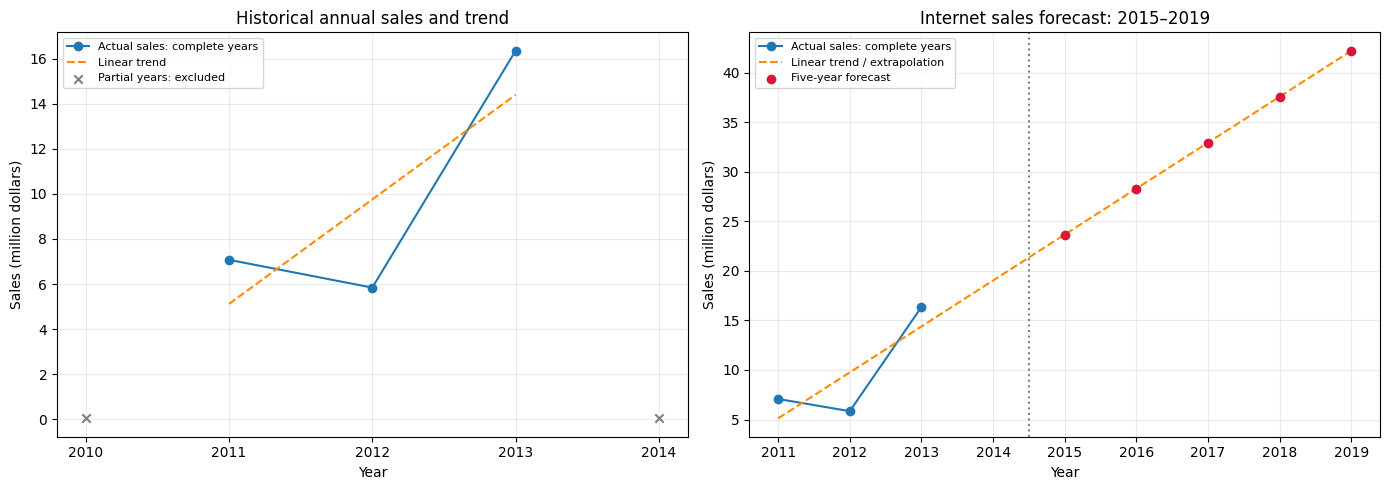

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(complete["Year"], complete["SalesAmount"] / 1_000_000,
             "o-", label="Actual sales: complete years")
axes[0].plot(complete["Year"], complete["Trend"] / 1_000_000,
             "--", color="darkorange", label="Linear trend")
partial = yearly[~yearly["Year"].between(2011, 2013)]
axes[0].scatter(partial["Year"], partial["SalesAmount"] / 1_000_000,
                marker="x", color="gray", label="Partial years: excluded", zorder=3)
axes[0].set(title="Historical annual sales and trend", xlabel="Year", ylabel="Sales (million dollars)")
axes[0].set_xticks(yearly["Year"])

axes[1].plot(complete["Year"], complete["SalesAmount"] / 1_000_000,
             "o-", label="Actual sales: complete years")
trend_years = np.arange(2011, future_years.max() + 1)
axes[1].plot(trend_years, (intercept + slope * (trend_years - 2011)) / 1_000_000,
             "--", color="darkorange", label="Linear trend / extrapolation")
axes[1].scatter(forecast["Year"], forecast["ForecastSales"] / 1_000_000,
                color="crimson", label="Five-year forecast", zorder=3)
axes[1].axvline(2014.5, color="gray", linestyle=":")
axes[1].set(title="Internet sales forecast: 2015–2019", xlabel="Year", ylabel="Sales (million dollars)")
axes[1].set_xticks(trend_years)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("Internet_Sales_Trend_and_Forecast.png", dpi=180, bbox_inches="tight")
plt.show()

The fitted trend slopes upward, although actual sales fall in 2012 and rise sharply in 2013. The model projects increasing sales from 2015 to 2019. These forecasts assume continued linear growth and do not account for changes in prices, product availability, or customer demand. No real-world conclusions should be drawn from this fictitious dataset.

